# Drawing: A New Way To Search — the full training pipeline

This notebook walks through every step of the project, from downloading QuickDraw to the final result tables.
It runs the same code as `src/` with the same settings and seeds. Set `MODE` below: `"quick"` trains every model
on 3 classes with tiny settings (about 10 minutes), `"full"` uses the exact settings behind the reported results
(many hours, a GPU is strongly recommended). All outputs go to `demonstration/output/<mode>/`, never to `results/`.

## About the saved outputs

This training notebook retains outputs from the original Linux/NVIDIA run. The saved `cuInit` / `CUDA_ERROR_NO_DEVICE` message means that run could not find an NVIDIA GPU; those saved messages do not describe the Mac environment. The Mac demo has been executed separately with TensorFlow on the CPU. Full training has not been repeated on this Mac. Use `demo.ipynb` or `Open Live Drawing.command` for the verified demonstration.


## 1. Setup and imports

The notebook runs from `demonstration/`, so the project root and `src/` are added to the import path. The data
loading and run bookkeeping (timing, accuracy, saving each run) come from `src/`, while the models themselves are
written out below. Quick mode deletes its own output folder first, so every quick run starts fresh.

In [1]:
MODE = "quick"  # "quick": 3 classes, tiny settings (~10 min) | "full": the settings behind the reported results

import os, sys, json, shutil, time, warnings
from pathlib import Path
# Works whether Jupyter starts in the project root or demonstration/.
ROOT = str(next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "src" / "data.py").is_file()))
os.chdir(os.path.join(ROOT, "demonstration"))
sys.path[:0] = [ROOT, os.path.join(ROOT, "src")]  # src modules import each other by name
sys.dont_write_bytecode = True                    # leave src/ untouched (no __pycache__ files)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from IPython.display import display

import common  # Run: seeds, times and saves each run
import data    # class lists, download, fixed split, loading

GPUS = tf.config.list_physical_devices("GPU")
for g in GPUS:
    tf.config.experimental.set_memory_growth(g, True)
HARDWARE = "GPU" if GPUS else "CPU"
print("GPU available:", bool(GPUS), [g.name for g in GPUS])

QUICK = MODE == "quick"
CLASSES = [3] if QUICK else [3, 10, 50]
OUTPUT = os.path.abspath(os.path.join("output", MODE))
if QUICK:
    shutil.rmtree(OUTPUT, ignore_errors=True)  # full runs keep their checkpoints and resume after a crash
common.set_out(OUTPUT)                          # every run below writes here, never to results/
T0 = time.time()
print("mode:", MODE, "| classes:", CLASSES, "| output:", OUTPUT)

I0000 00:00:1791885601.692709 1393607 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791885603.336355 1393607 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU available: False []
mode: quick | classes: [3] | output: /home/project/ml_miniproject/demonstration/output/quick


E0000 00:00:1791885604.483998 1393607 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


## 2. Download the data

Google publishes QuickDraw as one `.npy` file per class: every drawing is a 28×28 grayscale bitmap stored as
784 values from 0 to 255. A file is downloaded only if no valid copy (at least 20,000 drawings) is in `data/raw/`
already. Quick mode needs only the 3 classes it trains on; full mode needs all 50 (about 5.6 GB).

In [2]:
import urllib.parse, urllib.request
from concurrent.futures import ThreadPoolExecutor

def fetch(name):
    path = os.path.join(data.RAW, name + ".npy")
    if data._rows(path) is None:  # missing or broken: download again
        urllib.request.urlretrieve(data.URL + urllib.parse.quote(name) + ".npy", path + ".part")
        os.replace(path + ".part", path)
    return name, data._rows(path)

needed = data.CLASSES_3 if QUICK else data.CLASSES_50
os.makedirs(data.RAW, exist_ok=True)
with ThreadPoolExecutor(4) as ex:
    rows = dict(ex.map(fetch, needed))
bad = [n for n, r in rows.items() if r is None]
ok = [r for r in rows.values() if r]
print(f"{len(ok)} of {len(needed)} class files valid, {min(ok):,} to {max(ok):,} drawings each; bad: {bad}")

3 of 3 class files valid, 118,339 to 307,936 drawings each; bad: []


## 3. The fixed train / validation / test split

For each class we take the first 20,000 drawings and split them 80 / 10 / 10 with seed 42, as in the reference:
16,000 for training, 2,000 for validation and 2,000 for testing. The split is built once into `data/processed/`
and every model loads the same file; here we rebuild one class and check it matches the saved file exactly.

In [3]:
from sklearn.model_selection import train_test_split

def split_class(name, n=20_000):
    x = np.load(os.path.join(data.RAW, name + ".npy"), mmap_mode="r")[:n]
    train, rest = train_test_split(x, test_size=0.2, random_state=42)
    dev, test = train_test_split(rest, test_size=0.5, randodidm_state=42)
    return train, dev, test

for k in CLASSES:
    if not os.path.exists(data._path(k)):
        data.build(k)  # the same split for every class, stacked into data/processed/qd_{k}.npz
    data.verify(k)     # 16,000 / 2,000 / 2,000 per class, no leakage between the splits
xtr, ytr, xdv, ydv, xte, yte, names = data.load(3, "uint8")
tr, dv, te = split_class(names[0])
assert (tr == xtr[ytr == 0]).all() and (dv == xdv[ydv == 0]).all() and (te == xte[yte == 0]).all()
print(f"split of '{names[0]}' rebuilt: identical to the saved file")

qd_3.npz: OK (48000, 784) (6000, 784) (6000, 784)
split of 'eraser' rebuilt: identical to the saved file


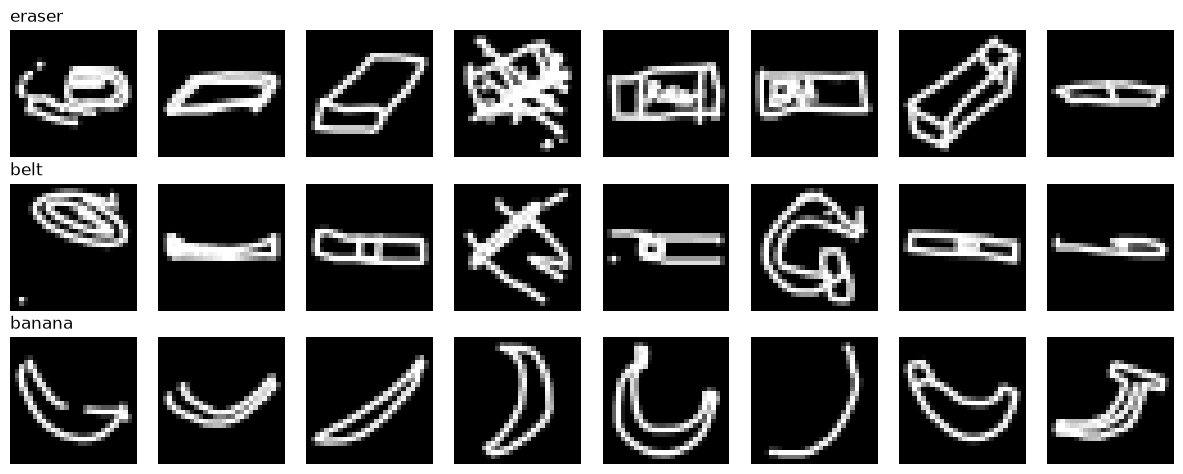

In [4]:
%matplotlib inline
fig, axs = plt.subplots(3, 8, figsize=(12, 4.8))
for c, row in enumerate(axs):
    for ax, img in zip(row, xtr[ytr == c][:8]):
        ax.imshow(img.reshape(28, 28), cmap="gray")  # white ink on black, values 0-255
        ax.axis("off")
    row[0].set_title(names[c], loc="left")
plt.tight_layout()
plt.show()

## 4. Logistic regression

A linear model on the 784 raw pixel values (0–255, no normalisation), as in the reference. L-BFGS stops after
100 iterations, before it fully converges, exactly like the original. Quick mode stops after 20 iterations.

In [5]:
from sklearn.linear_model import LogisticRegression

LR_ITER = 20 if QUICK else 100
for k in CLASSES:
    params = {"solver": "lbfgs", "max_iter": LR_ITER, "random_state": 0}  # lbfgs is multinomial for >2 classes
    with common.Run("LR", "logreg", k, "raw", params, seed=0) as r:
        xtr, ytr, xdv, ydv, xte, yte, names = data.load(k, "raw")
        clf = LogisticRegression(**params)
        with r.fit_timer(), warnings.catch_warnings():
            warnings.simplefilter("ignore")  # not converged at max_iter, as in the reference
            clf.fit(xtr, ytr)
        r.finish(ydv, clf.predict(xdv), names, yte, clf.predict(xte))

[LR_logreg_3_raw_s0] start 2026-10-13 15:30:05 concurrent=[]

[LR_logreg_3_raw_s0] dev_acc=79.7 test_acc=78.58 fit=3.14s total=3.41s

## 5. SVM with four kernels

Support vector machines with linear, polynomial, RBF and sigmoid kernels, on pixels scaled to [-1, 1] (the scaler
is fitted on the training set). Training stops after 500 iterations to match the reference, and only validation
accuracy is recorded. The SVMs run on 3 and 10 classes only; quick mode uses 50 iterations.

In [6]:
from sklearn.svm import SVC

KERNELS = {"linear": {}, "poly": {"degree": 5, "coef0": 1}, "rbf": {"gamma": 1}, "sigmoid": {"coef0": 1}}  # C=1
SVM_ITER = 50 if QUICK else 500
for k in ([3] if QUICK else [3, 10]):
    for kernel, extra in KERNELS.items():
        params = {"kernel": kernel, "max_iter": SVM_ITER, **extra}
        with common.Run("SVM", kernel, k, "scaled", params, seed=0) as r:
            xtr, ytr, xdv, ydv, _, _, names = data.load(k, "scaled")  # MinMax to [-1, 1], fitted on train
            clf = SVC(**params)
            with r.fit_timer(), warnings.catch_warnings():
                warnings.simplefilter("ignore")
                clf.fit(xtr, ytr)
            r.finish(ydv, clf.predict(xdv), names)

[SVM_linear_3_scaled_s0] start 2026-10-13 15:30:08 concurrent=[]

[SVM_linear_3_scaled_s0] dev_acc=41.73 test_acc=None fit=5.08s total=6.06s

[SVM_poly_3_scaled_s0] start 2026-10-13 15:30:14 concurrent=[]

[SVM_poly_3_scaled_s0] dev_acc=51.0 test_acc=None fit=5.37s total=6.29s

[SVM_rbf_3_scaled_s0] start 2026-10-13 15:30:20 concurrent=[]

[SVM_rbf_3_scaled_s0] dev_acc=71.7 test_acc=None fit=5.29s total=6.33s

[SVM_sigmoid_3_scaled_s0] start 2026-10-13 15:30:27 concurrent=[]

[SVM_sigmoid_3_scaled_s0] dev_acc=33.32 test_acc=None fit=5.51s total=6.38s

## 6. CNN V1–V4

Four small convolutional networks from the reference: V1 has two conv–pool blocks, V2 one, V3 is V2 without
pooling and V4 is V2 with a smaller dense layer. They train on raw 0–255 images (V1, V2) and on binarized images
(V1–V4) with Adam, batch 500 and 100 epochs (quick mode: 2). Unnormalised input sometimes makes a run collapse to
chance level, so a run still near chance after 5 epochs restarts with the next seed.

In [7]:
def build_cnn(version, k):
    L = [keras.Input((28, 28, 1)), layers.Conv2D(14, 3, activation="relu")]
    if version != "V3":
        L.append(layers.MaxPool2D(2))
    if version == "V1":
        L += [layers.Conv2D(14, 3, activation="relu"), layers.MaxPool2D(2)]
    L += [layers.Flatten(), layers.Dense(64 if version == "V4" else 128, activation="relu"),
          layers.Dense(k, activation="softmax")]
    return keras.Sequential(L)


class CollapseCheck(keras.callbacks.Callback):
    """Stop if validation accuracy is still below 1.5 / K after 5 epochs."""

    def __init__(self, k):
        super().__init__()
        self.limit, self.collapsed = 1.5 / k, False

    def on_epoch_end(self, epoch, logs=None):
        if epoch + 1 == 5 and logs["val_accuracy"] < self.limit:
            self.collapsed = True
            self.model.stop_training = True


build_cnn("V1", 50).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 14)     │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 14)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 14)     │         1,778 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 14)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 350)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        44,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         6,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,296 (208.19 KB)

 Trainable params: 53,296 (208.19 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
CNN_RUNS = [("V1", "raw"), ("V2", "raw"), ("V1", "binarized"), ("V2", "binarized"), ("V3", "binarized"), ("V4", "binarized")]
CNN_EPOCHS = 2 if QUICK else 100

def train_cnn(version, variant, k, seed, epochs):
    """One run; returns False if it collapsed."""
    params = {"epochs": epochs, "batch_size": 500, "optimizer": "adam", "lr": 0.001, "seed": seed}
    with common.Run("CNN", version, k, variant, params, hardware=HARDWARE, seed=seed) as r:
        keras.utils.set_random_seed(seed)
        xtr, ytr, xdv, ydv, xte, yte, names = data.load(k, "image" if variant == "raw" else "binarized_image")
        model = build_cnn(version, k)
        model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
        check = CollapseCheck(k)
        with r.fit_timer():
            hist = model.fit(xtr, ytr, batch_size=500, epochs=epochs, validation_data=(xdv, ydv),
                             verbose=2, callbacks=[r.checkpoint_cb(), check])
        if check.collapsed:
            shutil.rmtree(r.ckpt_dir, ignore_errors=True)  # the retry must start fresh, not resume
            return False
        r.history_csv(hist)
        r.curve_png(hist)
        final = version == "V2" and variant == "raw" and k == 50  # the only CNN scored on the test set
        pred_dev = model.predict(xdv, batch_size=500, verbose=0).argmax(1)
        pred_te = model.predict(xte, batch_size=500, verbose=0).argmax(1) if final else None
        r.finish(ydv, pred_dev, names, yte if final else None, pred_te)
        return True

for k in CLASSES:
    for version, variant in CNN_RUNS:
        for seed in range(7, 12):  # retry with the next seed after a collapse
            if train_cnn(version, variant, k, seed, CNN_EPOCHS):
                break
        else:
            raise RuntimeError(f"CNN {version} {variant} {k} collapsed with seeds 7-11")

[CNN_V1_3_raw_s7] start 2026-10-13 15:30:33 concurrent=[]

Epoch 1/2


96/96 - 4s - 38ms/step - accuracy: 0.7587 - loss: 1.7606 - val_accuracy: 0.8243 - val_loss: 0.6177


Epoch 2/2


96/96 - 2s - 22ms/step - accuracy: 0.8407 - loss: 0.4906 - val_accuracy: 0.8487 - val_loss: 0.4333


...

Epoch 1/2


96/96 - 3s - 27ms/step - accuracy: 0.7446 - loss: 3.2510 - val_accuracy: 0.8010 - val_loss: 0.5433


Epoch 2/2


96/96 - 2s - 16ms/step - accuracy: 0.8238 - loss: 0.4568 - val_accuracy: 0.8417 - val_loss: 0.4045


[CNN_V4_3_binarized_s7] dev_acc=84.17 test_acc=None fit=4.21s total=5.28s

## 7. Transfer learning

Four ImageNet networks (VGG19, MobileNet, ResNet50, InceptionV3) stay frozen; each 28×28 drawing is resized to
224×224 (299 for Inception), copied to 3 channels and passed through once, and the pooled features are saved.
A small head, Dense(128) → Dense(3), is then trained on those features, which gives the same result as training
with the frozen network attached but much faster. InceptionV3 then also fine-tunes its top two blocks together with
the head, starting from the saved output of its `mixed8` layer.

In [9]:
from train_transfer import APPS, Feats, merge, predict, subset  # model table and small data helpers from src

TL_EPOCHS = {"vgg19": 20, "mobilenet": 100, "resnet50": 100, "inception": 50}
STAGE2_EPOCHS, CUT, BATCH, K = 50, 249, 50, 3  # Inception fine-tunes layers 249+ (after mixed8)
LIMIT = None
if QUICK:
    TL_EPOCHS, STAGE2_EPOCHS = dict.fromkeys(TL_EPOCHS, 2), 1
    LIMIT = 300  # images used for anything that has to run through a full network here

def extract(base, fdir, limit=None):
    """Run every image once through the frozen network; save pooled features (and Inception's mixed8 output)."""
    os.makedirs(fdir, exist_ok=True)
    app, size = APPS[base]
    net = app(weights="imagenet", include_top=False, input_shape=(size, size, 3))
    outputs = [layers.GlobalAveragePooling2D()(net.output)]
    if base == "inception":
        outputs.append(net.layers[CUT - 1].output)  # mixed8, 8x8x1280
    extractor = keras.Model(net.input, outputs)
    xtr, _, xdv, _, xte, _, _ = data.load(K, "uint8")
    t0, pooled = time.time(), {}
    for split, x in (("train", xtr), ("dev", xdv), ("test", xte)):
        x = subset(x, limit and (limit if split == "train" else limit // 3))
        mix = None
        if base == "inception":  # float16 memory map: about 9.8 GB for all 60,000 images
            mix = np.lib.format.open_memmap(os.path.join(fdir, f"mixed8_{split}.npy"), mode="w+",
                                            dtype=np.float16, shape=(len(x), 8, 8, 1280))
        parts, i = [], 0
        for b in data.resized_batches(x, size, BATCH):  # resized to size x size x 3, values stay 0-255
            o = extractor.predict_on_batch(b)
            parts.append(o[0] if mix is not None else o)
            if mix is not None:
                mix[i:i + len(b)] = o[1].astype(np.float16)
            i += len(b)
        pooled[split] = np.concatenate(parts)
    np.savez(os.path.join(fdir, base + ".npz"), f_train=pooled["train"], f_dev=pooled["dev"], f_test=pooled["test"])
    with open(os.path.join(fdir, base + "_meta.json"), "w") as f:
        json.dump({"extract_time_s": round(time.time() - t0, 1), "dim": int(pooled["train"].shape[1])}, f)

def features(base):
    """Folder with the base's features: the full set made by src/ if present (read-only), else extract here."""
    src_dir = os.path.join(ROOT, "data", "features")
    if os.path.exists(os.path.join(src_dir, base + "_meta.json")):
        return src_dir, None
    fdir = os.path.join(OUTPUT, "features", f"limit{LIMIT}" if LIMIT else "all")
    if not os.path.exists(os.path.join(fdir, base + "_meta.json")):
        extract(base, fdir, LIMIT)
    return fdir, LIMIT

In [10]:
def train_tl(base):
    fdir, limit = features(base)
    meta = json.load(open(os.path.join(fdir, base + "_meta.json")))
    f = np.load(os.path.join(fdir, base + ".npz"))
    _, ytr, _, ydv, _, yte, names = data.load(K, "uint8")
    e1, e2 = TL_EPOCHS[base], (STAGE2_EPOCHS if base == "inception" else 0)
    params = {"stage1": {"epochs": e1, "optimizer": "adam(clipnorm=1)", "batch_size": BATCH},
              "stage2": {"epochs": e2, "optimizer": "sgd(lr=1e-4, momentum=0.9, clipnorm=1)",
                         "first_trainable_layer": CUT} if e2 else None,
              "option": "A (precomputed features)", "extract_time_s": meta["extract_time_s"]}
    with common.Run("TL", base, K, "resized", params, hardware=HARDWARE, seed=7) as r:
        keras.utils.set_random_seed(7)
        head = keras.Sequential([keras.Input((meta["dim"],)), layers.Dense(128, activation="relu"),
                                 layers.Dense(K, activation="softmax")])
        head.compile(keras.optimizers.Adam(clipnorm=1), "sparse_categorical_crossentropy", metrics=["accuracy"])
        n_dev = limit and limit // 3
        y_dev, y_test = subset(ydv, n_dev), subset(yte, n_dev)
        with r.fit_timer():
            hists = [head.fit(Feats(f["f_train"], subset(ytr, limit), True), epochs=e1, verbose=2,
                              validation_data=Feats(f["f_dev"], y_dev, False), callbacks=[r.checkpoint_cb()])]
        final, dev_in, test_in = head, f["f_dev"], f["f_test"]
        if e2:  # InceptionV3: fine-tune layers 249+ together with the head, starting from mixed8
            app, size = APPS[base]
            net = app(weights="imagenet", include_top=False, input_shape=(size, size, 3))
            top = keras.Model(net.layers[CUT - 1].output, net.output)
            top.trainable = True
            inp = keras.Input((8, 8, 1280))
            final = keras.Model(inp, head(layers.GlobalAveragePooling2D()(top(inp))))
            final.compile(keras.optimizers.SGD(1e-4, momentum=0.9, clipnorm=1), "sparse_categorical_crossentropy",
                          metrics=["accuracy"])
            m8 = {s: np.load(os.path.join(fdir, f"mixed8_{s}.npy"), mmap_mode="r") for s in ("train", "dev", "test")}
            m8 = {s: subset(x, LIMIT and (LIMIT if s == "train" else LIMIT // 3)) for s, x in m8.items()}
            y_dev, y_test = subset(ydv, LIMIT and LIMIT // 3), subset(yte, LIMIT and LIMIT // 3)
            ckpt2 = keras.callbacks.BackupAndRestore(os.path.join(r.ckpt_dir, "stage2"), delete_checkpoint=False)
            with r.fit_timer():
                hists.append(final.fit(Feats(m8["train"], subset(ytr, LIMIT), True), epochs=e2, verbose=2,
                                       validation_data=Feats(m8["dev"], y_dev, False), callbacks=[ckpt2]))
            dev_in, test_in = m8["dev"], m8["test"]
        h = merge(*hists)
        r.history_csv(h)
        r.curve_png(h)
        r.params["head_sec_per_epoch"] = round(r.fit_time / (e1 + e2), 2)
        r.finish(y_dev, predict(final, dev_in), names, y_test, predict(final, test_in))

for base in APPS:
    train_tl(base)

[TL_vgg19_3_resized_s7] start 2026-10-13 15:31:09 concurrent=[]

Epoch 1/2


960/960 - 4s - 5ms/step - accuracy: 0.9323 - loss: 0.2054 - val_accuracy: 0.9448 - val_loss: 0.1428


Epoch 2/2


960/960 - 3s - 3ms/step - accuracy: 0.9511 - loss: 0.1326 - val_accuracy: 0.9563 - val_loss: 0.1200


...

960/960 - 7s - 7ms/step - accuracy: 0.7962 - loss: 1.1323 - val_accuracy: 0.8560 - val_loss: 0.3826


Epoch 2/2


960/960 - 5s - 6ms/step - accuracy: 0.8646 - loss: 0.3488 - val_accuracy: 0.8590 - val_loss: 0.3726


6/6 - 10s - 2s/step - accuracy: 0.4467 - loss: 1.0942 - val_accuracy: 0.5300 - val_loss: 1.0076


[TL_inception_3_resized_s7] dev_acc=53.0 test_acc=53.0 fit=22.97s total=27.02s

## 8. XGBoost with Optuna

Our extension: gradient-boosted trees on the raw pixels. Optuna's TPE sampler searches seven settings to maximise
validation accuracy; every trial trains up to 3,000 rounds and stops after 50 rounds without improvement in
validation log-loss, and only the best trial is scored on the test set. The best setting is then trained without a
time limit until early stopping, which gave the final 50-class model (quick mode: 3 trials, 30 rounds).

In [11]:
warnings.filterwarnings("ignore", message="IProgress not found")  # optuna's progress bar, unused here
import optuna
import xgboost as xgb
import train_xgboost as txgb  # boost(): round-by-round training with early stopping and checkpoints

txgb.FIXED["device"] = "cuda" if GPUS else "cpu"  # src trains on the GPU; on a CPU the same model is only slower
FIXED = txgb.FIXED  # multi:softprob, mlogloss, hist, seed 0

def space(trial, wide=False):
    """Search space; max_depth stops at 9 (deeper trees ran out of an 8 GB GPU on 50 classes)."""
    if wide:  # wider ranges where the first search's best settings sat at an edge
        return {"max_depth": trial.suggest_int("max_depth", 6, 9),
                "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
                "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
                "subsample": trial.suggest_float("subsample", 0.6, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
                "gamma": trial.suggest_float("gamma", 0, 5),
                "reg_lambda": trial.suggest_float("reg_lambda", 1, 100, log=True)}
    return {"max_depth": trial.suggest_int("max_depth", 4, 9),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
            "min_child_weight": trial.suggest_float("min_child_weight", 1, 10),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
            "gamma": trial.suggest_float("gamma", 0, 5),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10, log=True)}

In [12]:
def xgb_search(k, wide=False, timeout=None, n_trials=None, start_from=None, rounds=3000, patience=50):
    name = f"xgb{k}_wide" if wide else f"xgb_{k}"
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    with common.Run("XGB", "xgb_wide" if wide else "xgb", k, "raw", hardware=HARDWARE, seed=0) as r:
        xtr, ytr, xdv, ydv, xte, yte, names = data.load(k, "raw")
        dtr = xgb.QuantileDMatrix(xtr, ytr)  # binned once, reused by every trial
        ddv = xgb.DMatrix(xdv, ydv)
        os.makedirs(r.ckpt_dir, exist_ok=True)
        best_path = os.path.join(r.ckpt_dir, "best.ubj")
        best = {"acc": -1.0}  # only the best trial's model is kept

        def objective(trial):
            p = space(trial, wide)
            t = time.time()
            bst = xgb.train({**FIXED, "num_class": k, **p}, dtr, rounds, evals=[(ddv, "dev")],
                            early_stopping_rounds=patience, verbose_eval=False)
            fit = time.time() - t
            bst = bst[: bst.best_iteration + 1]  # rounds up to the best validation loss
            acc = float(np.mean(bst.predict(ddv).argmax(1) == ydv))
            trial.set_user_attr("fit_time_s", round(fit, 2))
            trial.set_user_attr("rounds", bst.num_boosted_rounds())
            print(f"trial {trial.number}: dev_acc={100 * acc:.2f} rounds={bst.num_boosted_rounds()} fit={fit:.0f}s")
            if acc > best["acc"]:
                best.update(acc=acc, trial=trial.number)
                bst.save_model(best_path)
            return acc

        study = optuna.create_study(study_name=name, storage=txgb.storage(), direction="maximize",
                                    sampler=optuna.samplers.TPESampler(seed=0))
        if start_from:  # first trial: the best setting of an earlier study
            study.enqueue_trial(optuna.load_study(study_name=start_from, storage=txgb.storage()).best_params)
        t0 = time.time()
        study.optimize(objective, n_trials=n_trials, timeout=timeout, catch=(Exception,))
        bt = study.best_trial
        r.fit_time = bt.user_attrs["fit_time_s"]  # best trial only; the whole search is search_time_s
        r.params = {**bt.params, "rounds": bt.user_attrs["rounds"], "max_rounds": rounds, "early_stopping": patience,
                    "study": name, "trial": bt.number, "n_trials": len(study.trials),
                    "search_time_s": round(time.time() - t0, 1), "timeout_s": timeout}
        txgb.score(r, xgb.Booster(model_file=best_path), names, xdv, ydv, xte, yte)  # test set used once


def xgb_train(k, study, rounds=5000, patience=50):
    """The best setting of a study, trained until early stopping (no time limit)."""
    params = optuna.load_study(study_name=study, storage=txgb.storage()).best_params
    with common.Run("XGB", "xgb_extended", k, "raw", hardware=HARDWARE, seed=0) as r:
        xtr, ytr, xdv, ydv, xte, yte, names = data.load(k, "raw")
        dtr, ddv = xgb.QuantileDMatrix(xtr, ytr), xgb.DMatrix(xdv, ydv)
        model, res = txgb.boost(params, k, dtr, ddv, ydv, rounds, patience, r.ckpt_dir)
        os.replace(os.path.join(r.ckpt_dir, "curve.csv"), os.path.join(r.fig_dir, "curve.csv"))
        r.fit_time = res.pop("fit_time_s")
        r.params = {**params, **res, "max_rounds": rounds, "early_stopping": patience, "source_study": study}
        txgb.score(r, model, names, xdv, ydv, xte, yte)

The searches below are the ones behind the reported XGBoost results: 25 minutes on 3 classes, 2.5 hours on 10
classes and a 3-hour search with wider ranges on 10 classes. The final 50-class model uses the best 10-class
setting, because a search directly on 50 classes was too slow.

In [13]:
if QUICK:
    xgb_search(3, n_trials=3, rounds=30)
    xgb_train(3, "xgb_3", rounds=30)
else:
    xgb_search(3, timeout=25 * 60)
    xgb_search(10, timeout=2.5 * 3600)
    xgb_search(10, wide=True, timeout=3 * 3600, start_from="xgb_10")
    xgb_train(50, "xgb_10")

[XGB_xgb_3_raw_s0] start 2026-10-13 15:32:07 concurrent=[]

trial 0: dev_acc=88.85 rounds=30 fit=44s

trial 1: dev_acc=89.70 rounds=30 fit=42s

trial 2: dev_acc=81.48 rounds=30 fit=19s

[XGB_xgb_3_raw_s0] dev_acc=89.7 test_acc=89.27 fit=42.16s total=107.94s

[XGB_xgb_extended_3_raw_s0] start 2026-10-13 15:33:55 concurrent=[]

CAPPED_BY_ROUNDS: 30 rounds, best 30, dev_acc=89.70

[XGB_xgb_extended_3_raw_s0] dev_acc=89.7 test_acc=89.27 fit=55.5s total=57.02s

## 9. Results

These tables are read from `results/all_results.csv` (our full runs) and `results/reported.csv` (the report's
numbers); both files are only read. The first table compares the reported validation accuracy with ours, the second
puts all our models side by side. Accuracy is in %, one decimal place.

In [14]:
ours = pd.read_csv(os.path.join(ROOT, "results", "all_results.csv"))
reported = pd.read_csv(os.path.join(ROOT, "results", "reported.csv"))

rep = reported[reported.split == "dev"].merge(ours, on=["family", "model", "input", "classes"])
display(pd.DataFrame({"Family": rep.family, "Model": rep.model, "Input": rep.input, "Classes": rep.classes,
                      "Reported (%)": rep.acc, "Ours (%)": rep.dev_acc,
                      "Difference (points)": rep.dev_acc - rep.acc}).round(1))

,Family,Model,Input,Classes,Reported (%),Ours (%),Difference (points)
0,LR,logreg,raw,3,79.5,79.3,-0.2
1,LR,logreg,raw,10,64.6,65.8,1.2
2,LR,logreg,raw,50,43.9,43.3,-0.6
3,SVM,linear,scaled,3,40.8,43.3,2.5
4,SVM,linear,scaled,10,22.2,23.4,1.1
5,SVM,rbf,scaled,3,62.7,84.0,21.3
6,SVM,rbf,scaled,10,61.0,74.6,13.6
7,SVM,poly,scaled,3,51.7,66.7,15.0
8,SVM,poly,scaled,10,50.9,73.9,23.0
9,SVM,sigmoid,scaled,3,33.1,32.5,-0.6


In [15]:
xgb_final = ours[ours.family == "XGB"].drop_duplicates("classes", keep="last")  # the extended run replaces the first
cross = pd.concat([ours[ours.family.isin(["LR", "SVM", "CNN", "TL"])], xgb_final]).sort_values(
    ["classes", "dev_acc"], ascending=[True, False])
fmt = lambda v: "—" if pd.isna(v) else f"{v:.1f}"
display(pd.DataFrame({"Family": cross.family, "Model": cross.model, "Input": cross.input, "Classes": cross.classes,
                      "Validation (%)": cross.dev_acc.map(fmt), "Test (%)": cross.test_acc.map(fmt),
                      "Training time (s)": cross.fit_time_s.map(fmt)}).reset_index(drop=True))

,Family,Model,Input,Classes,Validation (%),Test (%),Training time (s)
0,TL,vgg19,resized,3,95.3,94.8,17.0
1,TL,resnet50,resized,3,95.3,95.2,84.1
2,TL,mobilenet,resized,3,94.6,93.8,82.3
3,TL,inception,resized,3,93.0,92.7,1210.3
4,CNN,V2,raw,3,91.7,—,37.7
5,XGB,xgb,raw,3,91.7,90.8,56.8
6,CNN,V1,raw,3,90.8,—,39.4
7,CNN,V2,binarized,3,90.1,—,38.5
8,CNN,V1,binarized,3,89.6,—,43.7
9,CNN,V4,binarized,3,89.2,—,36.9


For comparison, the runs this notebook just made (in quick mode these use tiny settings, so their accuracy is lower).

In [16]:
mine = pd.read_csv(os.path.join(OUTPUT, "all_results.csv"))
display(mine[["run_id", "fit_time_s", "dev_acc", "test_acc"]].round(1))
print(f"notebook run time: {(time.time() - T0) / 60:.1f} min")

,run_id,fit_time_s,dev_acc,test_acc
0,LR_logreg_3_raw_s0,3.1,79.7,78.6
1,SVM_linear_3_scaled_s0,5.1,41.7,NaN
2,SVM_poly_3_scaled_s0,5.4,51.0,NaN
3,SVM_rbf_3_scaled_s0,5.3,71.7,NaN
4,SVM_sigmoid_3_scaled_s0,5.5,33.3,NaN
5,CNN_V1_3_raw_s7,5.9,84.9,NaN
6,CNN_V2_3_raw_s7,4.5,87.8,NaN
7,CNN_V1_3_binarized_s7,5.6,83.0,NaN
8,CNN_V2_3_binarized_s7,4.5,84.6,NaN
9,CNN_V3_3_binarized_s7,5.9,85.6,NaN


notebook run time: 4.8 min
